Dataset shape: (50000, 2)
Positive reviews: 25000
Negative reviews: 25000
Training samples: 37500
Testing samples: 12500

NAIVE BAYES
Accuracy: 85.304
              precision    recall  f1-score   support

    negative       0.86      0.85      0.85      6250
    positive       0.85      0.86      0.85      6250

    accuracy                           0.85     12500
   macro avg       0.85      0.85      0.85     12500
weighted avg       0.85      0.85      0.85     12500



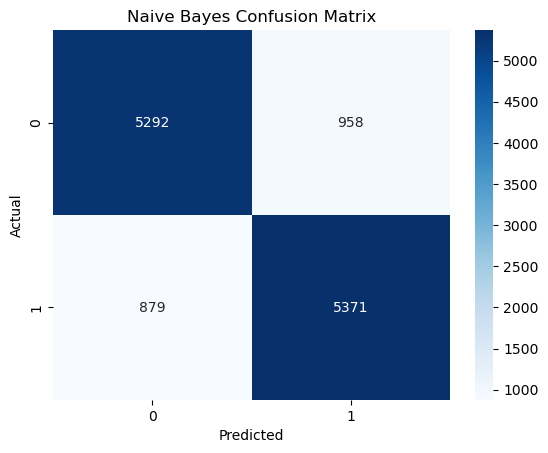


DECISION TREE
Accuracy: 72.048
              precision    recall  f1-score   support

    negative       0.72      0.72      0.72      6250
    positive       0.72      0.72      0.72      6250

    accuracy                           0.72     12500
   macro avg       0.72      0.72      0.72     12500
weighted avg       0.72      0.72      0.72     12500



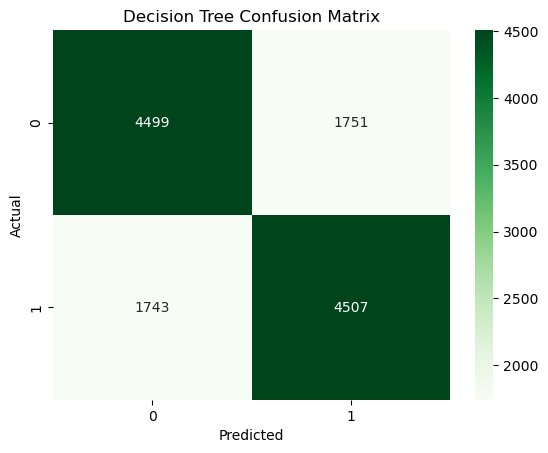


LOGISTIC REGRESSION
Accuracy: 89.056
              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      6250
    positive       0.88      0.90      0.89      6250

    accuracy                           0.89     12500
   macro avg       0.89      0.89      0.89     12500
weighted avg       0.89      0.89      0.89     12500



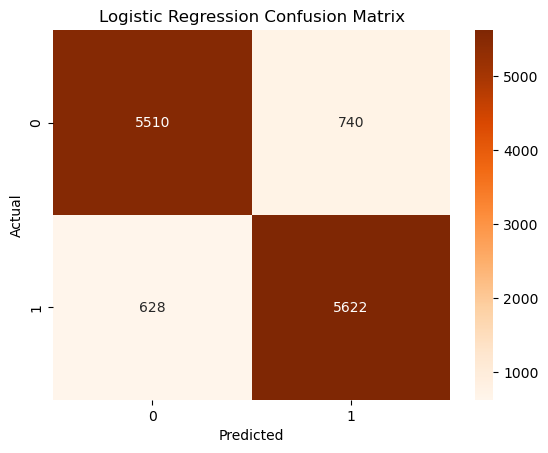


SUPPORT VECTOR MACHINE
Accuracy: 88.056
              precision    recall  f1-score   support

    negative       0.88      0.87      0.88      6250
    positive       0.88      0.89      0.88      6250

    accuracy                           0.88     12500
   macro avg       0.88      0.88      0.88     12500
weighted avg       0.88      0.88      0.88     12500



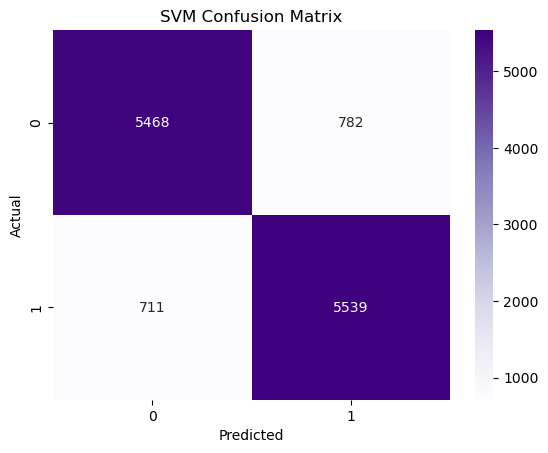


RANDOM FOREST
Accuracy: 85.21600000000001
              precision    recall  f1-score   support

    negative       0.84      0.87      0.85      6250
    positive       0.86      0.84      0.85      6250

    accuracy                           0.85     12500
   macro avg       0.85      0.85      0.85     12500
weighted avg       0.85      0.85      0.85     12500



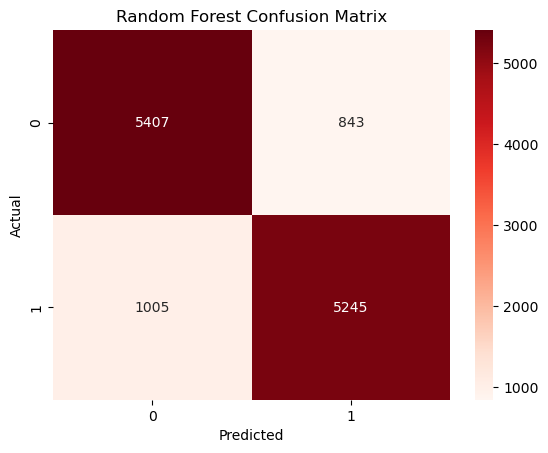


MODEL COMPARISON TABLE
          Algorithm  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
Logistic Regression         89.06          88.37       89.95         89.15
                SVM         88.06          87.63       88.62         88.12
        Naive Bayes         85.30          84.86       85.94         85.40
      Random Forest         85.22          86.15       83.92         85.02
      Decision Tree         72.05          72.02       72.11         72.07

Best Performing Algorithm: Logistic Regression


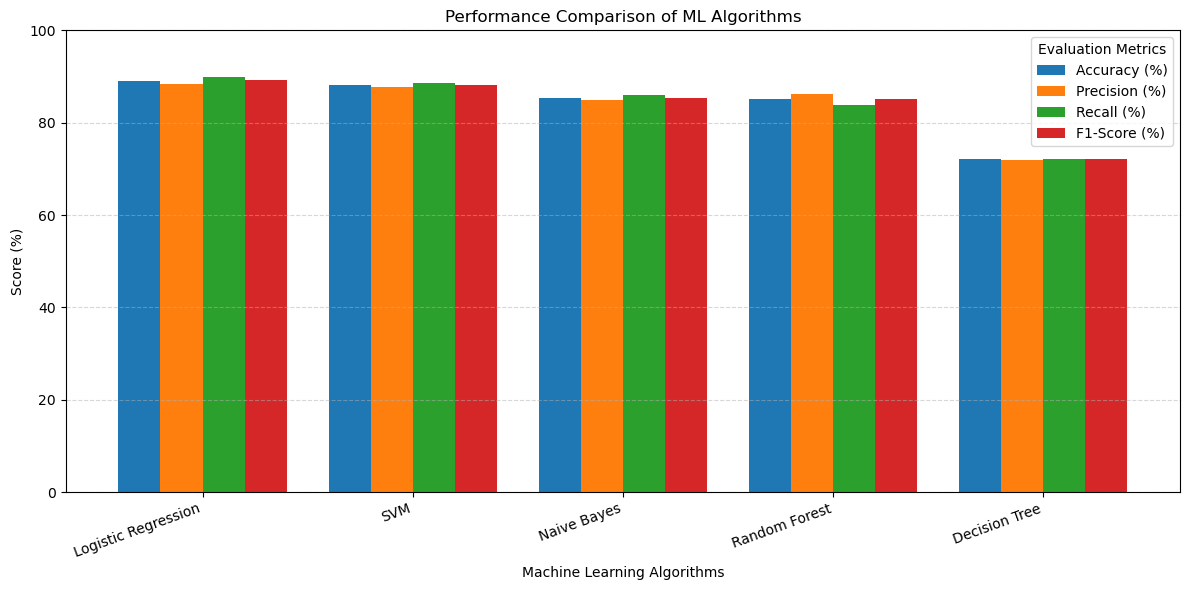

Best Model: Logistic Regression
Best Accuracy: 89.06 %


In [1]:
# ============================================================
# Program: Sentiment Analysis on IMDb Movie Reviews Dataset
# ============================================================

# Step 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score


# Step 2: Load the IMDb dataset
df = pd.read_csv("IMDB Dataset.csv")

X = df["review"]
y = df["sentiment"]

print("Dataset shape:", df.shape)
print("Positive reviews:", (y == "positive").sum())
print("Negative reviews:", (y == "negative").sum())


# Step 3: Convert text into numerical features
tfidf = TfidfVectorizer(stop_words="english", max_features=5000)
X = tfidf.fit_transform(X)


# Step 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


# Step 5: Create and train Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)

print("\nNAIVE BAYES")
print("Accuracy:", accuracy_score(y_test, nb_pred) * 100)
print(classification_report(y_test, nb_pred))

nb_cm = confusion_matrix(y_test, nb_pred, labels=["negative", "positive"])
sns.heatmap(nb_cm, annot=True, fmt="d", cmap="Blues")
plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Step 6: Create and train Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("\nDECISION TREE")
print("Accuracy:", accuracy_score(y_test, dt_pred) * 100)
print(classification_report(y_test, dt_pred))

dt_cm = confusion_matrix(y_test, dt_pred, labels=["negative", "positive"])
sns.heatmap(dt_cm, annot=True, fmt="d", cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Step 7: Create and train Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print("\nLOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(y_test, lr_pred) * 100)
print(classification_report(y_test, lr_pred))

lr_cm = confusion_matrix(y_test, lr_pred, labels=["negative", "positive"])
sns.heatmap(lr_cm, annot=True, fmt="d", cmap="Oranges")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Step 8: Create and train SVM model
svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

print("\nSUPPORT VECTOR MACHINE")
print("Accuracy:", accuracy_score(y_test, svm_pred) * 100)
print(classification_report(y_test, svm_pred))

svm_cm = confusion_matrix(y_test, svm_pred, labels=["negative", "positive"])
sns.heatmap(svm_cm, annot=True, fmt="d", cmap="Purples")
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Step 9: Create and train Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100, random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("\nRANDOM FOREST")
print("Accuracy:", accuracy_score(y_test, rf_pred) * 100)
print(classification_report(y_test, rf_pred))

rf_cm = confusion_matrix(y_test, rf_pred, labels=["negative", "positive"])
sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Reds")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Step 10: Compare all five models
results = []

for name, pred in [
    ("Naive Bayes", nb_pred),
    ("Decision Tree", dt_pred),
    ("Logistic Regression", lr_pred),
    ("SVM", svm_pred),
    ("Random Forest", rf_pred)
]:
    results.append([
        name,
        round(accuracy_score(y_test, pred) * 100, 2),
        round(precision_score(y_test, pred, pos_label="positive") * 100, 2),
        round(recall_score(y_test, pred, pos_label="positive") * 100, 2),
        round(f1_score(y_test, pred, pos_label="positive") * 100, 2)
    ])

comparison = pd.DataFrame(results, columns=[
    "Algorithm", "Accuracy (%)", "Precision (%)",
    "Recall (%)", "F1-Score (%)"
])

comparison = comparison.sort_values(
    by="F1-Score (%)", ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON TABLE")
print(comparison.to_string(index=False))

print("\nBest Performing Algorithm:", comparison.iloc[0]["Algorithm"])

 
metrics = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]

comparison.plot(
    x="Algorithm",
    y=metrics,
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Score (%)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Best Model

best_name = comparison.iloc[0]["Algorithm"]
print("Best Model:", best_name)

best_model = {
    "Naive Bayes": nb_model,
    "Decision Tree": dt_model,
    "Logistic Regression": lr_model,
    "SVM": svm_model,
    "Random Forest": rf_model
}[best_name]

print("Best Accuracy:",
      comparison.iloc[0]["Accuracy (%)"], "%")